<a href="https://colab.research.google.com/github/jk-nguyen/bmw-sales-analysis/blob/main/bmw_sales_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np

bmw_df = pd.read_csv('BMW sales data.csv')
def categorize_bmw_model(model):
    model = str(model)

    if "Series" in model:
        return "Series"
    elif model.startswith("i"):
        return "I"
    elif model.startswith("M"):
        return "M"
    elif model.startswith("X"):
        return "X"
    else:
        return "Other"

# Create new column
bmw_df["BMW_Model"] = bmw_df["Model"].apply(categorize_bmw_model)
bmw_df = bmw_df.rename(columns={'Model': 'Model_Type'})

for col in ['Model_Type', 'Region', 'Color', 'Fuel_Type', 'Transmission', 'Sales_Classification', 'BMW_Model']:
    bmw_df[col] = bmw_df[col].astype('category')

bmw_df['Price_USD'] = bmw_df['Price_USD'].astype(float)
bmw_df['Price_USD'] = bmw_df['Price_USD'].round(2)


# Display the info again to confirm the data type changes
bmw_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype   
---  ------                --------------  -----   
 0   Model_Type            50000 non-null  category
 1   Year                  50000 non-null  int64   
 2   Region                50000 non-null  category
 3   Color                 50000 non-null  category
 4   Fuel_Type             50000 non-null  category
 5   Transmission          50000 non-null  category
 6   Engine_Size_L         50000 non-null  float64 
 7   Mileage_KM            50000 non-null  int64   
 8   Price_USD             50000 non-null  float64 
 9   Sales_Volume          50000 non-null  int64   
 10  Sales_Classification  50000 non-null  category
 11  BMW_Model             50000 non-null  category
dtypes: category(7), float64(2), int64(3)
memory usage: 2.2 MB


In [ ]:
bmw_df = bmw_df.drop(columns=['Mileage_KM', 'Sales_Classification', 'Engine_Size_L'])

# Display the info again to confirm the columns are dropped
bmw_df.head()

,Model_Type,Year,Region,Color,Fuel_Type,Transmission,Price_USD,Sales_Volume,BMW_Model
0,7 Series,2024,Africa,Blue,Diesel,Automatic,42013.0,8472,Series
1,3 Series,2024,Africa,Grey,Electric,Manual,113482.0,4956,Series
2,M3,2024,Africa,White,Hybrid,Manual,91248.0,8772,M
3,i8,2024,Africa,White,Petrol,Manual,97980.0,6665,I
4,X5,2024,Africa,White,Petrol,Manual,72936.0,2487,X


In [ ]:
bmw_df.to_csv('bmw_sales_new.csv', index=False)
print('DataFrame saved as bmw_sales_load.csv')

DataFrame saved as bmw_sales_load.csv


In [ ]:
bmw_df.describe()

,Year,Price_USD,Sales_Volume
count,50000.000000,50000.000000,50000.000000
mean,2017.015700,75034.600900,5067.514680
std,4.324459,25998.248882,2856.767125
min,2010.000000,30000.000000,100.000000
25%,2013.000000,52434.750000,2588.000000
50%,2017.000000,75011.500000,5087.000000
75%,2021.000000,97628.250000,7537.250000
max,2024.000000,119998.000000,9999.000000


In [ ]:
bmw_df['Region'].value_counts()

,count
Region,
Asia,8454
Middle East,8373
North America,8335
Europe,8334
Africa,8253
South America,8251


In [ ]:
bmw_df['Fuel_Type'].value_counts()


,count
Fuel_Type,
Hybrid,12716
Petrol,12550
Electric,12471
Diesel,12263


In [ ]:
bmw_df['Transmission'].value_counts()

,count
Transmission,
Manual,25154
Automatic,24846


In [ ]:
bmw_df.groupby('Region')['Sales_Volume'].mean()

/tmp/ipykernel_3906/1054137801.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  bmw_df.groupby('Region')['Sales_Volume'].mean()


,Sales_Volume
Region,
Africa,5036.380952
Asia,5083.306955
Europe,5106.208063
Middle East,5055.131972
North America,5087.298020
South America,5035.973579


In [ ]:
bmw_df.groupby('Model')['Sales_Volume'].mean()

/tmp/ipykernel_3906/241070403.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  bmw_df.groupby('Model')['Sales_Volume'].mean()


,Sales_Volume
Model,
3 Series,5066.660065
5 Series,5029.947517
7 Series,5097.828118
M3,5064.512576
M5,5087.022778
X1,5121.676149
X3,5057.933956
X5,5061.232226
X6,5060.738276


In [ ]:
bmw_df.groupby('Fuel_Type')['Price_USD'].mean()

/tmp/ipykernel_3906/742208430.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  bmw_df.groupby('Fuel_Type')['Price_USD'].mean()


,Price_USD
Fuel_Type,
Diesel,75079.809671
Electric,75276.313207
Hybrid,74797.551746
Petrol,74990.419841


In [ ]:
# Filter for Hybrid cars in selected years
filtered_data = bmw_df[
    (bmw_df["Fuel_Type"] == "Hybrid") &
    (bmw_df["Year"].isin([2010, 2017, 2024]))
]

# View the results
filtered_data[["Year", "Model", "Sales_Volume"]]

,Year,Model,Sales_Volume
2,2024,M3,8772
6,2024,X3,3378
10,2024,X6,3613
11,2024,3 Series,8031
15,2024,X5,521
...,...,...,...
49980,2010,M3,1235
49982,2010,7 Series,6435
49983,2010,3 Series,9628
49992,2010,5 Series,205


In [ ]:
hybrid_sales = bmw_df[bmw_df["Fuel_Type"] == "Hybrid"]

hybrid_sales_by_year = hybrid_sales.groupby("Year")["Sales_Volume"].sum()

hybrid_sales_by_year

,Sales_Volume
Year,
2010,4415611
2011,4222305
2012,4347806
2013,4278494
2014,4434340
2015,4307029
2016,4111145
2017,4219927
2018,4021011


In [ ]:
columns_to_encode = ['Model', 'Region', 'Color', 'Fuel_Type', 'Transmission']

# Apply one-hot encoding
dummy_df = pd.get_dummies(bmw_df[columns_to_encode], prefix=columns_to_encode, dtype=int)

# Concatenate the new dummy variables with the original DataFrame
bmw_df = pd.concat([bmw_df, dummy_df], axis=1)

# Drop the original categorical columns
bmw_df = bmw_df.drop(columns=columns_to_encode)

# Display the first few rows of the updated DataFrame and its information
display(bmw_df.head())
bmw_df.info()

,Year,Price_USD,Sales_Volume,Model_3 Series,Model_5 Series,Model_7 Series,Model_M3,Model_M5,Model_X1,Model_X3,...,Color_Grey,Color_Red,Color_Silver,Color_White,Fuel_Type_Diesel,Fuel_Type_Electric,Fuel_Type_Hybrid,Fuel_Type_Petrol,Transmission_Automatic,Transmission_Manual
0,2024,42013.0,8472,0,0,1,0,0,0,0,...,0,0,0,0,1,0,0,0,1,0
1,2024,113482.0,4956,1,0,0,0,0,0,0,...,1,0,0,0,0,1,0,0,0,1
2,2024,91248.0,8772,0,0,0,1,0,0,0,...,0,0,0,1,0,0,1,0,0,1
3,2024,97980.0,6665,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,1,0,1
4,2024,72936.0,2487,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,1,0,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 32 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Year                    50000 non-null  int64  
 1   Price_USD               50000 non-null  float64
 2   Sales_Volume            50000 non-null  int64  
 3   Model_3 Series          50000 non-null  int64  
 4   Model_5 Series          50000 non-null  int64  
 5   Model_7 Series          50000 non-null  int64  
 6   Model_M3                50000 non-null  int64  
 7   Model_M5                50000 non-null  int64  
 8   Model_X1                50000 non-null  int64  
 9   Model_X3                50000 non-null  int64  
 10  Model_X5                50000 non-null  int64  
 11  Model_X6                50000 non-null  int64  
 12  Model_i3                50000 non-null  int64  
 13  Model_i8                50000 non-null  int64  
 14  Region_Africa           50000 non-null

In [ ]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

def simple_linear_regression(df, iv, dv='Sales_Volume'):
    X = df[[iv]]
    y = df[dv]

    X = sm.add_constant(X)  # add intercept
    model = sm.OLS(y, X).fit()

    print(f"\nRegression: {dv} ~ {iv}")
    print(model.summary())

In [ ]:
# Dependent variable
dv = 'Sales_Volume'

# Independent variables actually present in bmw_df
iv_list = [col for col in bmw_df.columns if col != dv]

# Optional: remove columns you do not want in regression
# keep only Price_USD + encoded dummy columns
iv_list = [col for col in iv_list if col == 'Price_USD' or
           col.startswith('Model_') or
           col.startswith('Region_') or
           col.startswith('Color_') or
           col.startswith('Fuel_Type_') or
           col.startswith('Transmission_')]

def run_simple_regression(df, iv, dv='Sales_Volume'):
    X = df[[iv]].astype(float)
    y = df[dv].astype(float)

    X = sm.add_constant(X)
    model = sm.OLS(y, X).fit()

    print(f"\n{'='*60}")
    print(f"Simple Linear Regression: {dv} ~ {iv}")
    print(f"{'='*60}")
    print(model.summary())

# Run regression for each IV separately
for iv in iv_list:
    run_simple_regression(bmw_df, iv, dv)


Simple Linear Regression: Sales_Volume ~ Price_USD
                            OLS Regression Results                            
Dep. Variable:           Sales_Volume   R-squared:                       0.000
Model:                            OLS   Adj. R-squared:                 -0.000
Method:                 Least Squares   F-statistic:                 0.0003165
Date:                Mon, 23 Mar 2026   Prob (F-statistic):              0.986
Time:                        07:40:57   Log-Likelihood:            -4.6882e+05
No. Observations:               50000   AIC:                         9.376e+05
Df Residuals:                   49998   BIC:                         9.377e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------


In [ ]:
import statsmodels.api as sm

# Drop all Region-related dummy variables
bmw_df_no_region = bmw_df.drop(columns=[col for col in bmw_df.columns if col.startswith("Region_")])

# Define dependent variable
y = bmw_df_no_region["Sales_Volume"]

# Define independent variables
X = bmw_df_no_region.drop("Sales_Volume", axis=1)

# Add constant (intercept)
X = sm.add_constant(X)

# Fit regression model
model = sm.OLS(y, X).fit()

# Display summary
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:           Sales_Volume   R-squared:                       0.000
Model:                            OLS   Adj. R-squared:                 -0.000
Method:                 Least Squares   F-statistic:                    0.5622
Date:                Mon, 23 Mar 2026   Prob (F-statistic):              0.945
Time:                        07:40:58   Log-Likelihood:            -4.6881e+05
No. Observations:               50000   AIC:                         9.377e+05
Df Residuals:                   49978   BIC:                         9.379e+05
Df Model:                          21                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                   1414

In [ ]:
import pandas as pd
import numpy as np
import statsmodels.api as sm

# Apply one-hot encoding to all remaining categorical columns in the DataFrame
# This ensures that any columns still of 'category' or 'object' dtype (like BMW_Model)
# are converted into numerical dummy variables.
bmw_df = pd.get_dummies(
    bmw_df,
    drop_first=True,  # Drop one category from each variable to avoid multicollinearity (dummy variable trap)
    dtype=int
)

# Define dependent variable
y = bmw_df['Sales_Volume']

# Define independent variables by dropping the dependent variable, Year, Region-related columns,
# and the specified variables: Mileage_KM, Engine_Size_L, and Sales_Classification_Low.
columns_to_drop_from_X = [
    'Sales_Volume',
    'Year',
    'Sales_Classification_Low' # Assuming 'Sales_Classification' becomes 'Sales_Classification_Low' after get_dummies
] + [col for col in bmw_df.columns if col.startswith('Region_')]

# Filter out columns that don't exist in bmw_df (to prevent errors if a column was already dropped or never existed)
columns_to_drop_from_X = [col for col in columns_to_drop_from_X if col in bmw_df.columns]

X = bmw_df.drop(columns=columns_to_drop_from_X)

# Add constant (intercept) to the independent variables
X = sm.add_constant(X)

# Fit regression model
model = sm.OLS(y, X).fit()

# Display summary
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:           Sales_Volume   R-squared:                       0.000
Model:                            OLS   Adj. R-squared:                 -0.000
Method:                 Least Squares   F-statistic:                    0.5689
Date:                Tue, 24 Mar 2026   Prob (F-statistic):              0.946
Time:                        00:35:51   Log-Likelihood:            -4.6881e+05
No. Observations:               50000   AIC:                         9.377e+05
Df Residuals:                   49977   BIC:                         9.379e+05
Df Model:                          22                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                4155.8861    

In [ ]:
import statsmodels.api as sm

# Define variables, using the one-hot encoded BMW_Model columns
X = bmw_df['Price_USD'] # independent variables
y = bmw_df['Sales_Volume']  # dependent variable

# Add constant (intercept)
X = sm.add_constant(X)

# Fit model
model_simple = sm.OLS(y, X).fit()

# Show summary
print(model_simple.summary())

                            OLS Regression Results                            
Dep. Variable:           Sales_Volume   R-squared:                       0.000
Model:                            OLS   Adj. R-squared:                 -0.000
Method:                 Least Squares   F-statistic:                 0.0003165
Date:                Tue, 24 Mar 2026   Prob (F-statistic):              0.986
Time:                        00:42:12   Log-Likelihood:            -4.6882e+05
No. Observations:               50000   AIC:                         9.376e+05
Df Residuals:                   49998   BIC:                         9.377e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       5066.8587     39.024    129.839      0.0

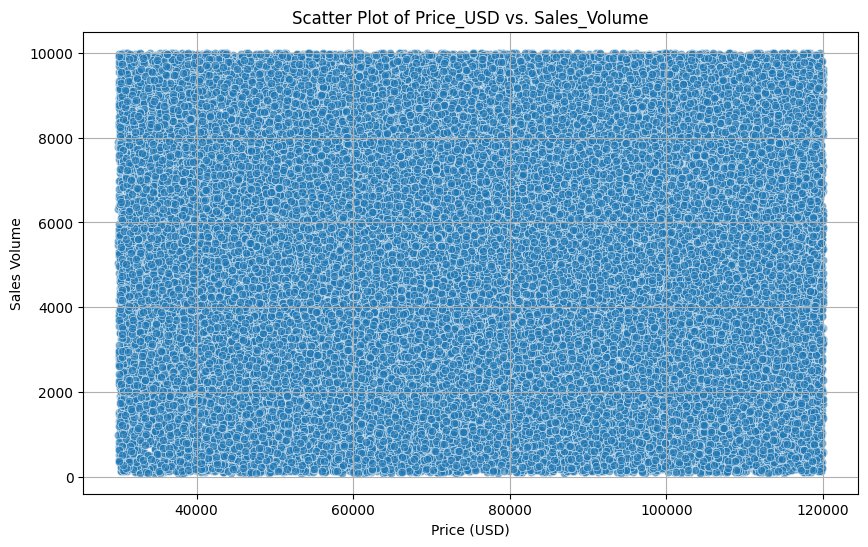

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.scatterplot(x='Price_USD', y='Sales_Volume', data=bmw_df, alpha=0.6)
plt.title('Scatter Plot of Price_USD vs. Sales_Volume')
plt.xlabel('Price (USD)')
plt.ylabel('Sales Volume')
plt.grid(True)
plt.show()

This scatter plot visualizes the individual data points, showing the 'Sales_Volume' for each car against its 'Price_USD'. The `alpha=0.6` parameter makes the points semi-transparent, which can help reveal areas with higher density of data points.

In [ ]:
import pandas as pd
import numpy as np

bmw_df = pd.read_csv('BMW sales data.csv')
for col in ['Model', 'Region', 'Color', 'Fuel_Type', 'Transmission', 'Sales_Classification']:
    bmw_df[col] = bmw_df[col].astype('category')

bmw_df['Price_USD'] = bmw_df['Price_USD'].astype(float)
bmw_df['Price_USD'] = bmw_df['Price_USD'].round(2)

most_popular_car = bmw_df.groupby(['Model', 'Transmission', 'Color', 'Fuel_Type'])['Sales_Volume'].sum().idxmax()
max_sales_volume = bmw_df.groupby(['Model', 'Transmission', 'Color', 'Fuel_Type'])['Sales_Volume'].sum().max()
least_popular_car = bmw_df.groupby(['Model', 'Transmission', 'Color', 'Fuel_Type'])['Sales_Volume'].sum().idxmin()
min_sales_volume = bmw_df.groupby(['Model', 'Transmission', 'Color', 'Fuel_Type'])['Sales_Volume'].sum().min()

print(f"The least popular BMW car configuration is: {least_popular_car}")
print(f"With a total sales volume of: {min_sales_volume}")

print(f"The most popular BMW car configuration is: {most_popular_car}")
print(f"With a total sales volume of: {max_sales_volume}")

The least popular BMW car configuration is: ('X1', 'Manual', 'Grey', 'Electric')
With a total sales volume of: 313501
The most popular BMW car configuration is: ('i3', 'Manual', 'Red', 'Diesel')
With a total sales volume of: 713720


/tmp/ipykernel_3906/804061898.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  most_popular_car = bmw_df.groupby(['Model', 'Transmission', 'Color', 'Fuel_Type'])['Sales_Volume'].sum().idxmax()
/tmp/ipykernel_3906/804061898.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  max_sales_volume = bmw_df.groupby(['Model', 'Transmission', 'Color', 'Fuel_Type'])['Sales_Volume'].sum().max()
/tmp/ipykernel_3906/804061898.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to ado

In [ ]:
least_popular_car = bmw_df.groupby(['Model', 'Transmission', 'Color', 'Fuel_Type'])['Sales_Volume'].sum().idxmin()
min_sales_volume = bmw_df.groupby(['Model', 'Transmission', 'Color', 'Fuel_Type'])['Sales_Volume'].sum().min()

print(f"The least popular BMW car configuration is: {least_popular_car}")
print(f"With a total sales volume of: {min_sales_volume}")